# Decision Transformer en GPU: entrenamiento y búsqueda de hiperparámetros

Este notebook:
1. Entrena varios DT con **búsqueda aleatoria** de hiperparámetros.
2. Elige la configuración con el **protocolo en validación** (no con la pérdida).
3. Reentrena la mejor configuración con **3 semillas** y dos variantes de `group_dropout` (0,0 y 0,3; la primaria es 0,3 para cold-start).
4. Compara con las líneas base y deja el test **reservado** (`RUN_TEST = False`).

`LOGS = "random" | "mixto" | "experto"` permite entrenar con los logs originales o con los del sistema anterior. Las líneas base se reajustan con los **mismos logs** que el modelo y, para `mixto`/`experto`, se agrega el sistema anterior con ε=0 como referencia. Los outputs van a `outputs/dt_gpu_<logs>/`.

Requisitos: ejecutar desde `2026/tp` con el entorno del TP instalado. Pensado para una VM con GPU NVIDIA A30 (24 GB), 128 cores y 396 GB de RAM: usa AMP (fp16), TF32 y batches grandes. El entrenamiento es rápido; el costo principal es la evaluación secuencial del protocolo (un forward batch-1 por paso de sesión). En CPU funciona igual pero tarda mucho más.

Para una prueba rápida de punta a punta, poner `SMOKE = True` en la próxima celda.

In [1]:
SMOKE = False

DATASET = "netflix"
LOGS = "random"          # "random" | "mixto" | "experto"
HORIZON = 20
RUN_NAME = "dt_gpu_smoke" if SMOKE else f"dt_gpu_{LOGS}"

HPO_TRIALS = 1 if SMOKE else 12
HPO_PER_GROUP = 2 if SMOKE else 50
HPO_TARGETS = [89] if SMOKE else [81, 89, 97]
HPO_CONDITIONS = [(0, True), (0, False)]
HPO_EVAL_SEEDS = (0,) if SMOKE else (0, 1)
MAX_BATCHES = 3 if SMOKE else None

FINAL_SEEDS = (0,) if SMOKE else (0, 1, 2)
FINAL_PER_GROUP = 2 if SMOKE else 50
FINAL_TARGETS = [89] if SMOKE else [65, 81, 89, 97]
EXTRAPOLATION_TARGETS = [100] if SMOKE else [110, 125]
SWEEP_TARGETS = FINAL_TARGETS + EXTRAPOLATION_TARGETS
GROUP_DROPOUT_VARIANTS = (0.0, 0.3)
EVAL_SEEDS = (0,) if SMOKE else (0, 1, 2)
EVAL_BATCH_SIZE = 32 if SMOKE else 512

RUN_TEST = False

In [2]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd()
if not (ROOT / "config_dataset.py").exists():
    raise RuntimeError("Ejecutar el notebook desde 2026/tp")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from modelos.dt import DTPolicy
from modelos.entrenamiento import train_dt
from modelos.evaluacion import evaluate_fast
from protocolo.datos import load_test, load_train, make_episodes, num_items, split_by_user
from protocolo.evaluar import baseline_factories, evaluate, write_reports
from protocolo.logs import PRESETS, PreviousSystem, logged_episodes, logs_cache
from protocolo.metricas import summarize
from protocolo.simulador import SessionConfig

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
if DEVICE == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision("high")

torch.manual_seed(0)
np.random.seed(0)
print(f"torch {torch.__version__} | device: {DEVICE} | amp: {USE_AMP}")
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))
if SMOKE:
    print("MODO SMOKE: corrida corta para validar el notebook")

torch 2.15.0+cu132 | device: cuda | amp: True
NVIDIA A30


In [3]:
paths = Path(f"outputs/{RUN_NAME}")
paths.mkdir(parents=True, exist_ok=True)

train_all = load_train(DATASET)
train, val = split_by_user(train_all)
N_ITEMS = num_items(DATASET)

if LOGS == "random":
    train_ep = make_episodes(train, HORIZON)
    val_ep = make_episodes(val, HORIZON)
    baseline_train = train
else:
    logged_train = logged_episodes(
        LOGS, train, train, N_ITEMS, HORIZON, seed=0,
        cache=logs_cache(DATASET, LOGS, "train"),
    )
    logged_val = logged_episodes(
        LOGS, val, train, N_ITEMS, HORIZON, seed=1,
        cache=logs_cache(DATASET, LOGS, "val"),
    )
    train_ep, val_ep = logged_train.episodes, logged_val.episodes
    baseline_train = logged_train.logged_users()


def stratified_subset(users, per_group, seed=0):
    rng = np.random.default_rng(seed)
    subset = []
    for group in range(8):
        members = [u for u in users if u.group == group]
        take = min(per_group, len(members))
        idx = rng.choice(len(members), size=take, replace=False)
        subset.extend(members[i] for i in idx)
    return subset


hpo_users = stratified_subset(val, HPO_PER_GROUP, seed=0)
final_users = stratified_subset(val, FINAL_PER_GROUP, seed=1)

print(f"logs: {LOGS} | catálogo: {N_ITEMS} ítems")
print(f"episodios: train {train_ep.items.shape[0]:,} | val {val_ep.items.shape[0]:,}")
print("retorno medio de un episodio de train:", float(train_ep.ratings.sum(1).mean()))
print(f"usuarios de val: HPO {len(hpo_users)} | final {len(final_users)}")

logs: random | catálogo: 752 ítems
episodios: train 73,827 | val 8,275
retorno medio de un episodio de train: 64.29808877510938
usuarios de val: HPO 400 | final 400


## 1. Búsqueda de hiperparámetros

Búsqueda aleatoria sobre `d_model`, `n_layers`, `n_heads`, `dropout`, `lr`, `weight_decay`, `group_dropout`, `batch_size` y `epochs`.

Cada trial se entrena una vez y se evalúa en un subconjunto estratificado de validación (50 usuarios por grupo) con el protocolo: warm-up 0, grupo visible y oculto, y varios retornos pedidos dentro del soporte de train. El score es el **normalizado medio** de las dos condiciones con el mejor retorno pedido del trial, promediado sobre **2 semillas de evaluación** para reducir ruido.

La evaluación usa `evaluate_fast`: agrupa sesiones y hace un forward por paso para todo el batch, con resultados equivalentes al protocolo oficial (verificado en `tests/test_evaluacion.py`). La cross-entropy se guarda sólo como diagnóstico: con logs uniformes queda cerca de `log(n_items)` y **no mide calidad** (rúbrica). La selección final se hace sobre otra muestra de validación (semilla distinta) y se reportan media y desvío entre semillas de entrenamiento.

In [4]:
rng = np.random.default_rng(123)


def sample_config():
    d_model = int(rng.choice([128, 192, 256]))
    head_options = [h for h in (4, 8) if d_model % h == 0]
    return {
        "d_model": d_model,
        "n_heads": int(rng.choice(head_options)),
        "n_layers": int(rng.choice([2, 3, 4])),
        "dropout": float(rng.choice([0.0, 0.1, 0.2])),
        "lr": float(np.exp(rng.uniform(np.log(3e-4), np.log(2e-3)))),
        "weight_decay": float(rng.choice([1e-2, 1e-1])),
        "group_dropout": float(rng.choice([0.0, 0.3])),
        "batch_size": int(rng.choice([512, 1024, 2048])),
        "epochs": int(rng.choice([20, 30, 40])),
    }


def evaluate_dt(model, users, targets, conditions, seeds):
    rows = []
    for target in targets:
        policy = DTPolicy(model, target_return=target)
        for warmup, visible in conditions:
            cfg = SessionConfig(horizon=HORIZON, warmup=warmup, group_visible=visible)
            raw = evaluate_fast(
                policy, users, N_ITEMS, cfg, seeds=seeds, batch_size=EVAL_BATCH_SIZE
            )
            s = summarize(raw)
            by_group = summarize(raw, by="group")
            row = {
                "target": target,
                "warmup": warmup,
                "visible": visible,
                "normalized": float(s[("normalized", "mean")].iloc[0]),
                "ci95": float(s[("normalized", "ci95")].iloc[0]),
                "return": float(s[("return", "mean")].iloc[0]),
                "hit_rate": float(s[("hit_rate", "mean")].iloc[0]),
                "ndcg@10": float(s[("ndcg@10", "mean")].iloc[0]),
                "precision@10": float(s[("precision@10", "mean")].iloc[0]),
            }
            for group in range(8):
                row[f"return_g{group}"] = float(by_group[("return", "mean")].loc[group])
                row[f"normalized_g{group}"] = float(by_group[("normalized", "mean")].loc[group])
            rows.append(row)
    return pd.DataFrame(rows)

In [5]:
SMOKE_CONFIG = {
    "d_model": 32, "n_heads": 2, "n_layers": 1, "dropout": 0.0,
    "lr": 1e-3, "weight_decay": 1e-2, "group_dropout": 0.3,
    "batch_size": 32, "epochs": 1,
}

hpo_rows = []
for trial in range(HPO_TRIALS):
    cfg = SMOKE_CONFIG if SMOKE else sample_config()
    start = time.time()
    model, history, val_ce = train_dt(
        train_ep, val_ep, N_ITEMS,
        seed=0,
        max_batches=MAX_BATCHES,
        device=DEVICE,
        amp=USE_AMP,
        output=paths / "hpo" / f"trial{trial:02d}",
        verbose=not SMOKE,
        **cfg,
    )
    scores = evaluate_dt(model, hpo_users, HPO_TARGETS, HPO_CONDITIONS, seeds=HPO_EVAL_SEEDS)
    per_target = scores.groupby("target")["normalized"].mean()
    target = float(per_target.idxmax())
    score = float(per_target.max())
    row = {**cfg, "target": target, "score": score, "val_ce": val_ce,
           "minutos": (time.time() - start) / 60}
    hpo_rows.append(row)
    print(f"trial {trial}: score={score:.3f} | target={target:.0f} | ce={val_ce:.4f} "
          f"| {row['minutos']:.1f} min | {cfg}")
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

hpo = pd.DataFrame(hpo_rows).sort_values("score", ascending=False).reset_index(drop=True)
hpo.to_csv(paths / "hpo_resultados.csv", index=False)
hpo.round(4)

epoch   1/20 | train 6.6229 | val 6.6148 | mejor 6.6148 | lr 4.77e-05
epoch   2/20 | train 6.6115 | val 6.6109 | mejor 6.6109 | lr 1.28e-04
epoch   3/20 | train 6.6109 | val 6.6115 | mejor 6.6109 | lr 2.38e-04
epoch   4/20 | train 6.6113 | val 6.6114 | mejor 6.6109 | lr 3.47e-04
epoch   5/20 | train 6.6103 | val 6.6221 | mejor 6.6109 | lr 4.27e-04
epoch   6/20 | train 6.6082 | val 6.6027 | mejor 6.6027 | lr 4.56e-04
epoch   7/20 | train 6.5991 | val 6.6092 | mejor 6.6027 | lr 4.50e-04
epoch   8/20 | train 6.5936 | val 6.5930 | mejor 6.5930 | lr 4.33e-04
epoch   9/20 | train 6.5896 | val 6.5893 | mejor 6.5893 | lr 4.06e-04
epoch  10/20 | train 6.5875 | val 6.5923 | mejor 6.5893 | lr 3.69e-04
epoch  11/20 | train 6.5862 | val 6.5873 | mejor 6.5873 | lr 3.26e-04
epoch  12/20 | train 6.5846 | val 6.5884 | mejor 6.5873 | lr 2.78e-04
epoch  13/20 | train 6.5835 | val 6.5878 | mejor 6.5873 | lr 2.27e-04
epoch  14/20 | train 6.5825 | val 6.5874 | mejor 6.5873 | lr 1.76e-04
epoch  15/20 | train

,d_model,n_heads,n_layers,dropout,lr,weight_decay,group_dropout,batch_size,epochs,target,score,val_ce,minutos
0,128,4,3,0.2,0.0010,0.01,0.0,1024,40,97.0,0.5790,6.5801,1.5897
1,128,8,2,0.0,0.0014,0.10,0.0,1024,40,97.0,0.5665,6.5869,1.1965
2,192,4,3,0.2,0.0015,0.10,0.0,1024,30,97.0,0.5619,6.5824,1.6606
3,128,8,3,0.0,0.0005,0.01,0.0,1024,20,97.0,0.5615,6.5869,0.9057
4,256,4,2,0.0,0.0003,0.01,0.0,1024,30,97.0,0.5590,6.5901,1.3077
5,192,4,3,0.1,0.0005,0.10,0.3,2048,20,97.0,0.5586,6.5898,1.0765
6,192,8,3,0.2,0.0005,0.10,0.3,2048,40,97.0,0.5571,6.5883,2.1927
7,192,8,3,0.2,0.0005,0.01,0.3,512,40,97.0,0.5557,6.5871,2.4481
8,256,4,3,0.0,0.0003,0.01,0.0,2048,30,97.0,0.5552,6.5891,1.7323
9,128,8,3,0.2,0.0005,0.10,0.3,512,30,97.0,0.5535,6.5862,1.4298


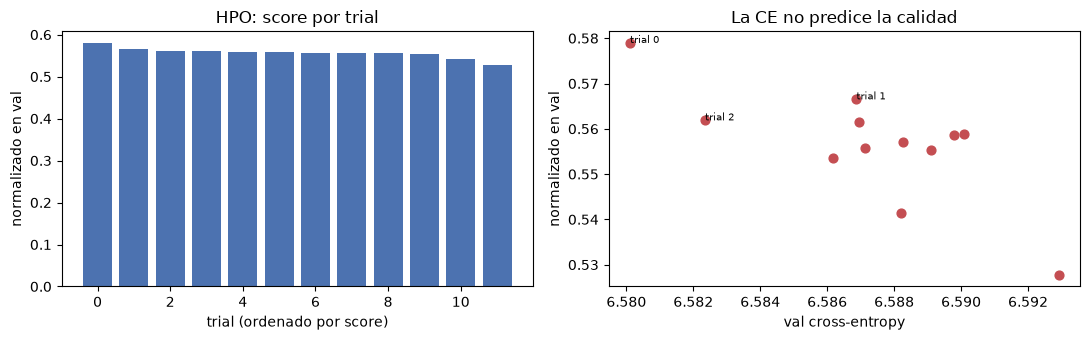

Mejor configuración:


,0
d_model,128.000000
n_heads,4.000000
n_layers,3.000000
dropout,0.200000
lr,0.000966
weight_decay,0.010000
group_dropout,0.000000
batch_size,1024.000000
epochs,40.000000
target,97.000000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(np.arange(len(hpo)), hpo["score"], color="#4c72b0")
axes[0].set_xlabel("trial (ordenado por score)")
axes[0].set_ylabel("normalizado en val")
axes[0].set_title("HPO: score por trial")

axes[1].scatter(hpo["val_ce"], hpo["score"], s=40, color="#c44e52")
axes[1].set_xlabel("val cross-entropy")
axes[1].set_ylabel("normalizado en val")
axes[1].set_title("La CE no predice la calidad")
for idx, row in hpo.head(3).iterrows():
    axes[1].annotate(f"trial {idx}", (row["val_ce"], row["score"]), fontsize=7)
plt.tight_layout()
plt.show()

print("Mejor configuración:")
display(hpo.head(1).T)

## 2. Entrenamiento final con la mejor configuración

Se entrena la mejor configuración con **dos variantes** de `group_dropout`: 0,0 y 0,3, con las mismas 3 semillas. La variante **primaria se elige en validación** (la de mejor normalizado medio con su mejor retorno dentro del soporte); la otra queda como comparación. Así, si forzar 0,3 no ayuda, no se reporta como primaria sólo por diseño.

Cada semilla guarda `modelo.pt`, `config.json` e `historial.csv` en `outputs/<RUN_NAME>/final_gd<valor>/seed<k>/`.

In [7]:
best = hpo.iloc[0]
integer_keys = {"d_model", "n_heads", "n_layers", "batch_size", "epochs"}
best_base_cfg = {
    key: int(best[key]) if key in integer_keys else float(best[key])
    for key in ["d_model", "n_heads", "n_layers", "dropout", "lr",
                "weight_decay", "group_dropout", "batch_size", "epochs"]
}
print("Configuración base (HPO):", best_base_cfg)
print("Variantes de group_dropout:", GROUP_DROPOUT_VARIANTS)

models, histories = {}, {}
for gd in GROUP_DROPOUT_VARIANTS:
    cfg = {**best_base_cfg, "group_dropout": float(gd)}
    for seed in FINAL_SEEDS:
        model, history, val_ce = train_dt(
            train_ep, val_ep, N_ITEMS,
            seed=seed,
            max_batches=MAX_BATCHES,
            device=DEVICE,
            amp=USE_AMP,
            output=paths / f"final_gd{gd}" / f"seed{seed}",
            **cfg,
        )
        models[(gd, seed)] = model
        histories[(gd, seed)] = history

Configuración base (HPO): {'d_model': 128, 'n_heads': 4, 'n_layers': 3, 'dropout': 0.2, 'lr': 0.0009661705275750276, 'weight_decay': 0.01, 'group_dropout': 0.0, 'batch_size': 1024, 'epochs': 40}
Variantes de group_dropout: (0.0, 0.3)
epoch   1/40 | train 6.6210 | val 6.6123 | mejor 6.6123 | lr 5.45e-05
epoch   2/40 | train 6.6123 | val 6.6107 | mejor 6.6107 | lr 1.01e-04
epoch   3/40 | train 6.6118 | val 6.6110 | mejor 6.6107 | lr 1.75e-04
epoch   4/40 | train 6.6121 | val 6.6113 | mejor 6.6107 | lr 2.71e-04
epoch   5/40 | train 6.6122 | val 6.6116 | mejor 6.6107 | lr 3.83e-04
epoch   6/40 | train 6.6119 | val 6.6097 | mejor 6.6097 | lr 5.03e-04
epoch   7/40 | train 6.6116 | val 6.6096 | mejor 6.6096 | lr 6.23e-04
epoch   8/40 | train 6.6079 | val 6.6017 | mejor 6.6017 | lr 7.35e-04
epoch   9/40 | train 6.6010 | val 6.5940 | mejor 6.5940 | lr 8.31e-04
epoch  10/40 | train 6.5973 | val 6.6066 | mejor 6.5940 | lr 9.05e-04
epoch  11/40 | train 6.5940 | val 6.5890 | mejor 6.5890 | lr 9.51e

### Recargar modelos finales (si se reinició el kernel)

Si el kernel se reinició después del entrenamiento, esta celda reconstruye `models` e `histories` desde los checkpoints guardados. Si venís de entrenar en la misma sesión, podés saltearla.

In [8]:
#from modelos.entrenamiento import load_dt

#models, histories = {}, {}
#for gd in GROUP_DROPOUT_VARIANTS:
#    for seed in FINAL_SEEDS:
#        base = paths / f"final_gd{gd}" / f"seed{seed}"
#        models[(gd, seed)] = load_dt(base / "modelo.pt", device=DEVICE)
#        histories[(gd, seed)] = pd.read_csv(base / "historial.csv")
#print(f"modelos recargados: {len(models)}")

In [9]:
#fig, ax = plt.subplots(figsize=(8, 4))
#for (gd, seed), history in histories.items():
#    ax.plot(history["epoch"], history["train_loss"], "--", alpha=0.35, label=f"train gd{gd} s{seed}")
#    ax.plot(history["epoch"], history["val_loss"], "-", alpha=0.8, label=f"val gd{gd} s{seed}")
#ax.axhline(np.log(N_ITEMS), color="gray", ls=":", label="log(n_items)")
#ax.set_xlabel("época")
#ax.set_ylabel("cross-entropy")
#ax.set_title("Curvas de entrenamiento (sin recortes)")
#ax.legend(fontsize=6, ncol=2)
#plt.tight_layout()
#plt.show()

## 3. Evaluación en validación

Se barre el retorno pedido y las 4 condiciones (warm-up 0/5 × grupo visible/oculto) con las 3 semillas de entrenamiento. El barrido incluye valores **por encima del máximo de train** (110 y 125) para estudiar extrapolación, pero **la selección del retorno sólo considera valores dentro del soporte** de entrenamiento.

Se reportan normalizado, IC 95 % por usuario, retorno, hit rate, NDCG@10 y precision@10. La comparación completa con las líneas base se guarda en `comparacion_val.csv`. La variante primaria y el retorno final se eligen en validación: para cada variante se toma su mejor retorno dentro del soporte y gana la de mayor normalizado medio; luego se comparan ambas.

In [10]:
conditions = [(0, True), (0, False), (5, True), (5, False)]

rows = []
for (gd, seed), model in models.items():
    df = evaluate_dt(model, final_users, SWEEP_TARGETS, conditions, EVAL_SEEDS)
    df["group_dropout"] = gd
    df["seed"] = seed
    rows.append(df)
val_dt = pd.concat(rows, ignore_index=True)
val_dt.to_csv(paths / "dt_val_barrido.csv", index=False)

variant_rows = []
for gd, subset in val_dt.groupby("group_dropout"):
    support = subset[subset["target"].isin(FINAL_TARGETS)]
    by_target = support.groupby("target")["normalized"].mean().sort_values(ascending=False)
    variant_rows.append({
        "group_dropout": gd,
        "best_target": float(by_target.index[0]),
        "score": float(by_target.iloc[0]),
    })
variants = pd.DataFrame(variant_rows).sort_values("score", ascending=False).reset_index(drop=True)
print("Variantes DT: mejor retorno dentro del soporte y normalizado medio en val")
display(variants.round(3))

primary_gd = float(variants.loc[0, "group_dropout"])
best_target = float(variants.loc[0, "best_target"])
print(f"Variante primaria: group_dropout={primary_gd} | retorno elegido={best_target:.0f}")

all_targets = val_dt[val_dt["group_dropout"] == primary_gd].groupby("target")["normalized"].mean()
print("Barrido completo, incluida extrapolación (variante primaria):")
print(all_targets.round(3).to_string())

for gd in GROUP_DROPOUT_VARIANTS:
    subset = val_dt[(val_dt["group_dropout"] == gd) & (val_dt["target"] == best_target)]
    print(f"DT gd={gd} con objetivo {best_target:.0f}: normalizado por semilla")
    display(subset.pivot_table(index="seed", columns=["warmup", "visible"], values="normalized").round(3))
    print(f"DT gd={gd}: media y desvío entre semillas")
    display(subset.groupby(["warmup", "visible"])["normalized"].agg(["mean", "std"]).round(3))

Variantes DT: mejor retorno dentro del soporte y normalizado medio en val


,group_dropout,best_target,score
0,0.0,97.0,0.576
1,0.3,97.0,0.558


Variante primaria: group_dropout=0.0 | retorno elegido=97
Barrido completo, incluida extrapolación (variante primaria):
target
65    -0.074
81     0.404
89     0.542
97     0.576
110    0.575
125    0.574
DT gd=0.0 con objetivo 97: normalizado por semilla


warmup       0             5       
visible  False  True   False  True 
seed                               
0        0.549  0.596  0.569  0.604
1        0.546  0.588  0.569  0.596
2        0.555  0.582  0.569  0.591

DT gd=0.0: media y desvío entre semillas


mean    std
warmup visible              
0      False    0.550  0.005
       True     0.588  0.007
5      False    0.569  0.000
       True     0.597  0.007

DT gd=0.3 con objetivo 97: normalizado por semilla


warmup       0             5       
visible  False  True   False  True 
seed                               
0        0.532  0.572  0.553  0.587
1        0.542  0.558  0.556  0.567
2        0.533  0.562  0.556  0.577

DT gd=0.3: media y desvío entre semillas


mean    std
warmup visible              
0      False    0.536  0.005
       True     0.564  0.007
5      False    0.555  0.001
       True     0.577  0.010

In [11]:
factories = baseline_factories(baseline_train, N_ITEMS)
if LOGS != "random":
    _, temperature = PRESETS[LOGS]
    factories["sistema_anterior_eps0"] = lambda: PreviousSystem.fit(
        train, N_ITEMS, 0.0, temperature, np.random.default_rng(0)
    )

base_rows = []
for name, factory in factories.items():
    for warmup, visible in conditions:
        cfg = SessionConfig(horizon=HORIZON, warmup=warmup, group_visible=visible)
        s = summarize(evaluate(factory(), final_users, N_ITEMS, cfg, seeds=EVAL_SEEDS))
        base_rows.append({
            "policy": name, "warmup": warmup, "visible": visible,
            "normalized": float(s[("normalized", "mean")].iloc[0]),
            "ci95": float(s[("normalized", "ci95")].iloc[0]),
            "return": float(s[("return", "mean")].iloc[0]),
            "hit_rate": float(s[("hit_rate", "mean")].iloc[0]),
            "ndcg@10": float(s[("ndcg@10", "mean")].iloc[0]),
            "precision@10": float(s[("precision@10", "mean")].iloc[0]),
        })
baselines = pd.DataFrame(base_rows)
baselines.to_csv(paths / "baselines_val.csv", index=False)

dt_rows = []
for gd in GROUP_DROPOUT_VARIANTS:
    subset = val_dt[(val_dt["group_dropout"] == gd) & (val_dt["target"] == best_target)]
    grouped = subset.groupby(["warmup", "visible"]).agg(
        normalized=("normalized", "mean"),
        ci95=("ci95", "mean"),
        retorno=("return", "mean"),
        hit_rate=("hit_rate", "mean"),
        ndcg10=("ndcg@10", "mean"),
        precision10=("precision@10", "mean"),
    ).reset_index()
    grouped = grouped.rename(
        columns={"retorno": "return", "ndcg10": "ndcg@10", "precision10": "precision@10"}
    )
    grouped["policy"] = f"dt_gd{gd}_{best_target:.0f}"
    dt_rows.append(grouped)

comparison_long = pd.concat([baselines, *dt_rows], ignore_index=True)
comparison_long.to_csv(paths / "comparacion_val.csv", index=False)
comparison = comparison_long.pivot_table(
    index="policy", columns=["warmup", "visible"], values="normalized"
)
print("Comparación en validación (normalizado, 0=azar, 1=oráculo):")
display(comparison.round(3))
print("Métricas completas en", paths / "comparacion_val.csv")

Comparación en validación (normalizado, 0=azar, 1=oráculo):


warmup               0             5       
visible          False  True   False  True 
policy                                     
dt_gd0.0_97      0.550  0.588  0.569  0.597
dt_gd0.3_97      0.536  0.564  0.555  0.577
group_mean       0.565  0.656  0.580  0.666
group_posterior  0.617  0.656  0.640  0.666
item_mean        0.565  0.565  0.580  0.580
popularity      -0.028 -0.028 -0.020 -0.020
random           0.005  0.005 -0.002 -0.002

Métricas completas en outputs/dt_gpu_random/comparacion_val.csv


### Retorno pedido vs. obtenido

Con warm-up 0 y grupo visible se grafica el retorno **obtenido** contra el **pedido**, con la diagonal, el máximo de train y el retorno elegido en validación. Más allá del máximo de train es extrapolación. Se muestra el agregado y, debajo, cada grupo por separado (la consigna pide resultados por grupo además del agregado).

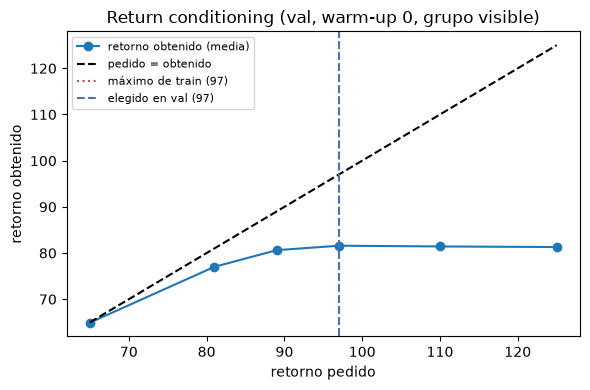

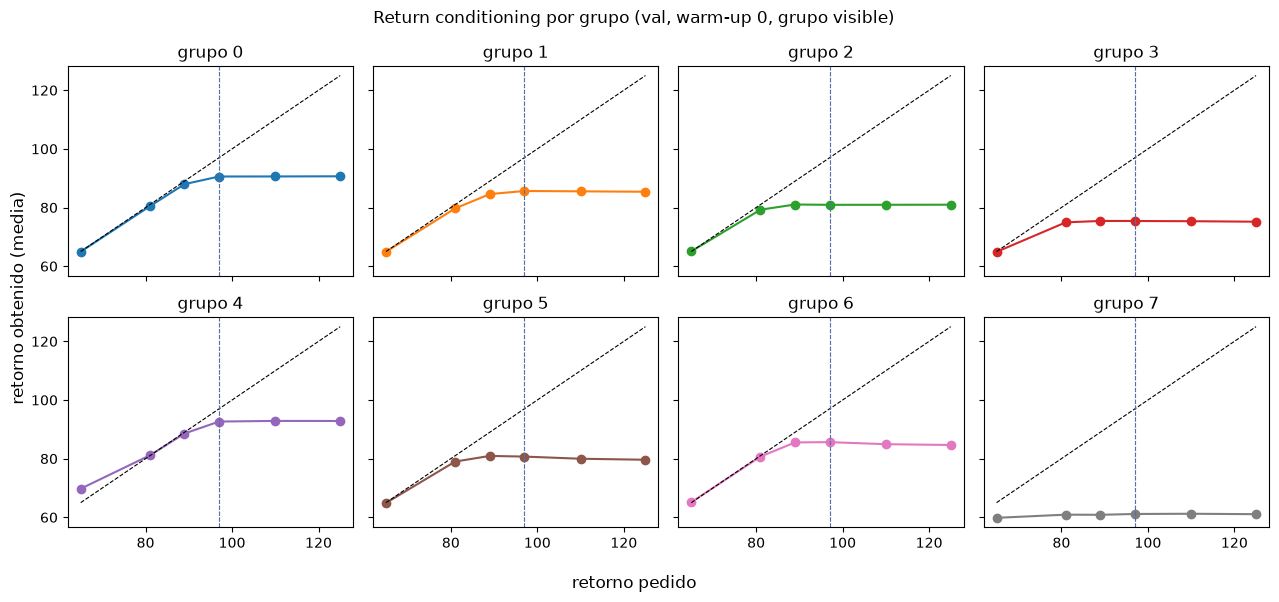

In [12]:
primary = val_dt[val_dt["group_dropout"] == primary_gd]
w0_visible = primary[(primary["warmup"] == 0) & primary["visible"]]
mean_return = w0_visible.groupby("target")["return"].mean()
train_max = float(train_ep.returns_to_go()[:, 0].max())
axis_max = max(mean_return.index.max(), train_max)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(mean_return.index, mean_return.values, "o-", label="retorno obtenido (media)")
ax.plot([mean_return.index.min(), axis_max], [mean_return.index.min(), axis_max], "k--", label="pedido = obtenido")
ax.axvline(train_max, color="#c44e52", ls=":", label=f"máximo de train ({train_max:.0f})")
ax.axvline(best_target, color="#4c72b0", ls="--", label=f"elegido en val ({best_target:.0f})")
ax.set_xlabel("retorno pedido")
ax.set_ylabel("retorno obtenido")
ax.set_title("Return conditioning (val, warm-up 0, grupo visible)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

group_cols = [f"return_g{g}" for g in range(8)]
group_returns = w0_visible.groupby("target")[group_cols].mean()
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True, sharey=True)
for group, ax in enumerate(axes.ravel()):
    ax.plot(group_returns.index, group_returns[f"return_g{group}"], "o-", color=f"C{group}")
    ax.plot([group_returns.index.min(), axis_max], [group_returns.index.min(), axis_max], "k--", lw=0.8)
    ax.axvline(train_max, color="#c44e52", ls=":", lw=0.8)
    ax.axvline(best_target, color="#4c72b0", ls="--", lw=0.8)
    ax.set_title(f"grupo {group}")
fig.supxlabel("retorno pedido")
fig.supylabel("retorno obtenido (media)")
fig.suptitle("Return conditioning por grupo (val, warm-up 0, grupo visible)")
plt.tight_layout()
plt.show()

## 4. Checklist antes de tocar test

- [ ] La configuración, el retorno y la variante primaria se eligieron **sólo con validación**, dentro del soporte.
- [ ] Se reporta la extrapolación (110/125) por separado de la selección.
- [ ] Se comparan las variantes `group_dropout=0.0` y `0.3`; la primaria es la mejor en validación.
- [ ] Se reportan 3 semillas de entrenamiento: media y desvío entre semillas, separados del IC 95 % por usuario.
- [ ] Las líneas base se ajustaron con el mismo split de train.
- [ ] Las curvas de entrenamiento se guardaron sin recortes.
- [ ] `RUN_TEST = True` se usa una sola vez, al final, para la tabla final.

Si además se entrena con logs `mixto` (sección 6 del TP), repetir todo con los logs generados y reajustar las líneas base con esos mismos logs.

In [13]:
if RUN_TEST:
    test = load_test(DATASET)
    frames = []
    for seed in FINAL_SEEDS:
        model = models[(primary_gd, seed)]
        policy = DTPolicy(model, target_return=best_target)
        for warmup, visible in conditions:
            cfg = SessionConfig(horizon=HORIZON, warmup=warmup, group_visible=visible)
            df = evaluate_fast(policy, test, N_ITEMS, cfg, seeds=EVAL_SEEDS, batch_size=EVAL_BATCH_SIZE)
            df["policy"] = f"dt_seed{seed}"
            df["warmup"] = warmup
            df["group_visible"] = visible
            frames.append(df)
    for name, factory in factories.items():
        for warmup, visible in conditions:
            cfg = SessionConfig(horizon=HORIZON, warmup=warmup, group_visible=visible)
            df = evaluate(factory(), test, N_ITEMS, cfg, seeds=EVAL_SEEDS)
            df["policy"] = name
            df["warmup"] = warmup
            df["group_visible"] = visible
            frames.append(df)
    test_results = pd.concat(frames, ignore_index=True)
    write_reports(test_results, paths / "eval" / "test")
else:
    print("RUN_TEST=False: test reservado. Cambiarlo a True una sola vez, al final.")

RUN_TEST=False: test reservado. Cambiarlo a True una sola vez, al final.
